# Loan Approval Prediction — HDFC Bank Ltd.
**Mini Project | AI / Machine Learning | Semester 2**

## 1. Problem Definition
- **Problem:** HDFC Bank wants to speed up loan processing. Checking every application by hand is slow.
- **Objective:** Build a supervised ML model that predicts whether a loan application should be **Approved** or **Rejected**.
- **Inputs:** Applicant details — income, co-applicant income, loan amount, loan term, credit history, employment, education, marital status, dependents, property area.
- **Output:** `Loan_Status` → Approved (Y) / Rejected (N).
- **ML type:** The output is a **category**, not a number → this is a **Classification** problem.

In [1]:
import pandas as pd
import numpy as np
import matplotlib
try:
    get_ipython()            # running inside Jupyter -> show charts inline
except NameError:
    matplotlib.use("Agg")    # running as a script -> just save charts
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

APPROVED, REJECTED, THIRD = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(f"outputs/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 2. Data Collection
Dataset: **Loan Prediction Dataset** (Kaggle / Analytics Vidhya "Loan Prediction Problem"),
downloaded from a public GitHub mirror. 614 past loan applications, 13 columns.

In [2]:
df = pd.read_csv("data/loan_data.csv")
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


## 3. Data Understanding
Shape, data types, missing values, duplicates and the target.

In [3]:
print("Shape (rows, columns):", df.shape)
print("\nData types:\n", df.dtypes)

Shape (rows, columns): (614, 13)

Data types:
 Loan_ID                  str
Gender                   str
Married                  str
Dependents               str
Education                str
Self_Employed            str
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area            str
Loan_Status              str
dtype: object


In [4]:
missing = df.isnull().sum()
print("Missing values per column:\n", missing[missing > 0].sort_values(ascending=False))
print("\nDuplicate rows:", df.duplicated().sum())
print("\nTarget distribution:\n", df["Loan_Status"].value_counts())
print("\n% approved:", round((df["Loan_Status"] == "Y").mean() * 100, 1))

Missing values per column:
 Credit_History      50
Self_Employed       32
LoanAmount          22
Dependents          15
Loan_Amount_Term    14
Gender              13
Married              3
dtype: int64

Duplicate rows: 0

Target distribution:
 Loan_Status
Y    422
N    192
Name: count, dtype: int64

% approved: 68.7


**Observations**
- 614 rows, 13 columns. 8 categorical columns, 5 numerical.
- 7 columns have missing values — `Credit_History` (50) is the most important one.
- No duplicate rows.
- Target is **imbalanced**: about 69% Approved, 31% Rejected. So accuracy alone can be misleading.

## 4. Data Preprocessing
| Step | What we did | Why |
|---|---|---|
| Drop `Loan_ID` | Removed | It is just an ID — no predictive value |
| Missing categorical | Filled with **mode** (most common value) | Few missing values; mode keeps the most likely category |
| Missing `LoanAmount` | Filled with **median** | Loan amount is skewed; median is not pulled by outliers |
| Missing `Loan_Amount_Term` | Filled with **mode** (360 months) | Almost every loan is 360 months |
| `Dependents` "3+" | Changed to 3 | So it becomes a number |
| Categorical → numbers | Yes/No columns mapped to 1/0, `Property_Area` one-hot encoded | ML models only understand numbers |
| Outliers in income | **Kept**, then log-transformed (Step 6) | They are real high earners, not errors |
| Scaling | StandardScaler for Logistic Regression only | LR is sensitive to scale; trees are not |

In [5]:
data = df.drop(columns=["Loan_ID"]).copy()

for col in ["Gender", "Married", "Dependents", "Self_Employed", "Credit_History", "Loan_Amount_Term"]:
    data[col] = data[col].fillna(data[col].mode()[0])
data["LoanAmount"] = data["LoanAmount"].fillna(data["LoanAmount"].median())

data["Dependents"] = data["Dependents"].replace("3+", "3").astype(int)
data["Gender"] = data["Gender"].map({"Male": 1, "Female": 0})
data["Married"] = data["Married"].map({"Yes": 1, "No": 0})
data["Education"] = data["Education"].map({"Graduate": 1, "Not Graduate": 0})
data["Self_Employed"] = data["Self_Employed"].map({"Yes": 1, "No": 0})
data["Loan_Status"] = data["Loan_Status"].map({"Y": 1, "N": 0})

print("Missing values after cleaning:", data.isnull().sum().sum())

Missing values after cleaning: 0


## 5. Exploratory Data Analysis (EDA)
Each chart answers one question.

**Q1. What does the target look like?**

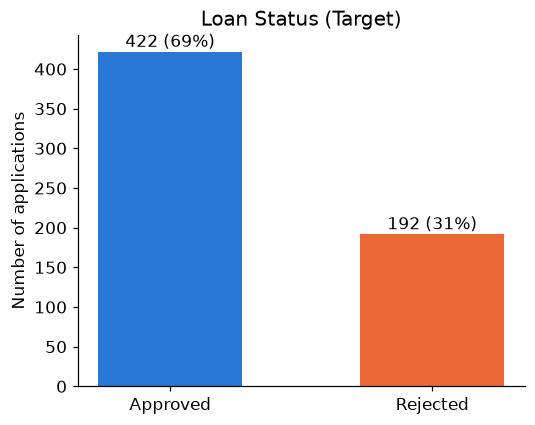

In [6]:
counts = df["Loan_Status"].map({"Y": "Approved", "N": "Rejected"}).value_counts()
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(counts.index, counts.values, color=[APPROVED, REJECTED], width=0.55)
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 6,
            f"{int(b.get_height())} ({b.get_height() / len(df):.0%})", ha="center")
ax.set_title("Loan Status (Target)")
ax.set_ylabel("Number of applications")
save(fig, "01_target")

*Observation:* 422 approved vs 192 rejected → imbalanced. A "model" that approves everyone already gets ~69% accuracy, so our model must beat that.

**Q2. Does credit history affect approval?**

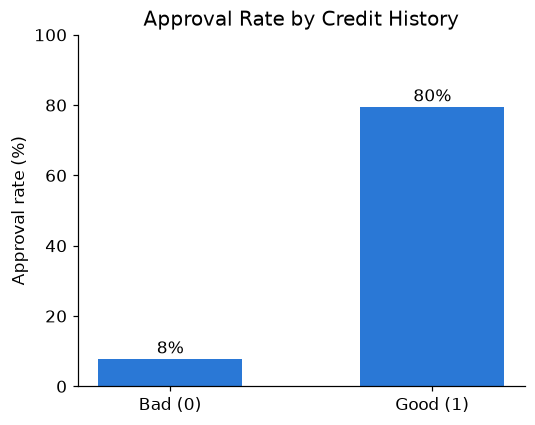

In [7]:
def approval_rate_plot(col, labels, title, name):
    rate = df.groupby(col)["Loan_Status"].apply(lambda s: (s == "Y").mean() * 100)
    rate.index = [labels.get(i, i) for i in rate.index]
    fig, ax = plt.subplots(figsize=(5, 4))
    bars = ax.bar(rate.index.astype(str), rate.values, color=APPROVED, width=0.55)
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1.5, f"{b.get_height():.0f}%", ha="center")
    ax.set_ylim(0, 100)
    ax.set_ylabel("Approval rate (%)")
    ax.set_title(title)
    save(fig, name)

approval_rate_plot("Credit_History", {0.0: "Bad (0)", 1.0: "Good (1)"},
                   "Approval Rate by Credit History", "02_credit_history")

*Observation:* Good credit history → ~80% approved. Bad credit history → only ~8% approved. **Credit history is the strongest signal.**

**Q3. Does property area matter?**

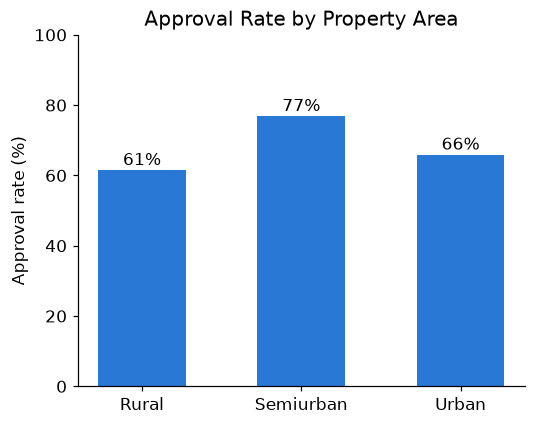

In [8]:
approval_rate_plot("Property_Area", {}, "Approval Rate by Property Area", "03_property_area")

*Observation:* Semiurban applicants are approved most often (~77%), Rural least (~61%).

**Q4. Are there outliers in income and loan amount?**

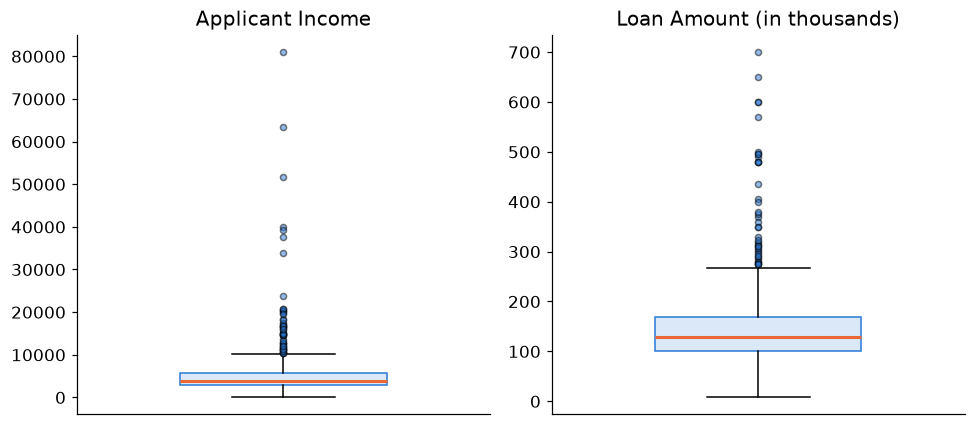

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, col, title in zip(axes, ["ApplicantIncome", "LoanAmount"],
                          ["Applicant Income", "Loan Amount (in thousands)"]):
    ax.boxplot(df[col].dropna(), widths=0.5, patch_artist=True,
               boxprops=dict(facecolor="#dbe8f8", color=APPROVED),
               medianprops=dict(color=REJECTED, linewidth=2),
               flierprops=dict(marker="o", markerfacecolor=APPROVED, markersize=4, alpha=0.5))
    ax.set_title(title)
    ax.set_xticks([])
save(fig, "04_outliers")

*Observation:* Both are **right-skewed** with many high outliers (some incomes above 60,000). These are real rich applicants, so we keep them and use a **log transform** to reduce skew.

**Q5. Do approved and rejected applicants differ in income?**

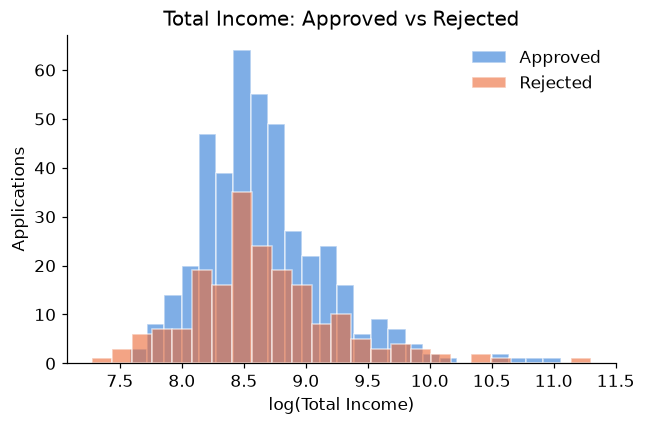

In [10]:
df["TotalIncome"] = df["ApplicantIncome"] + df["CoapplicantIncome"]
fig, ax = plt.subplots(figsize=(6, 4))
for status, color, label in [("Y", APPROVED, "Approved"), ("N", REJECTED, "Rejected")]:
    ax.hist(np.log(df.loc[df["Loan_Status"] == status, "TotalIncome"]), bins=25,
            alpha=0.6, color=color, label=label, edgecolor="white")
ax.set_xlabel("log(Total Income)")
ax.set_ylabel("Applications")
ax.set_title("Total Income: Approved vs Rejected")
ax.legend(frameon=False)
save(fig, "05_income_vs_status")

*Observation:* The two distributions overlap almost completely → **income alone does not decide approval**. This is surprising and an important insight.

**Q6. Which variables move together? (Correlation)**

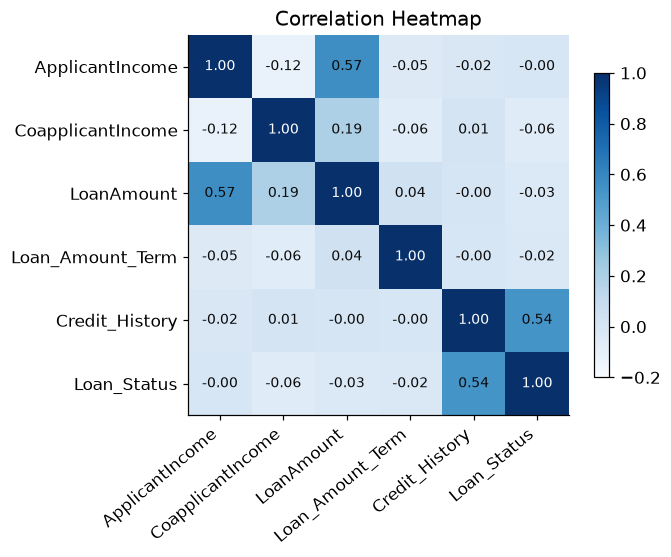

In [11]:
num = data[["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term",
            "Credit_History", "Loan_Status"]]
corr = num.corr()
fig, ax = plt.subplots(figsize=(6.5, 5.2))
im = ax.imshow(corr, cmap="Blues", vmin=-0.2, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                color="white" if v > 0.6 else "#0b0b0b", fontsize=9)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation Heatmap")
save(fig, "06_correlation")

*Observation:* `Credit_History` has the highest correlation with `Loan_Status` (~0.54). `ApplicantIncome` and `LoanAmount` are moderately related (~0.57) — richer people ask for bigger loans.

## 6. Feature Engineering / Selection
Raw income columns do not represent the problem well. A bank cares about **ability to repay**, so we create:
- **TotalIncome** = ApplicantIncome + CoapplicantIncome (household income) → then `log` to reduce skew
- **LoanAmount_log** = log(LoanAmount) → reduces skew
- **EMI** = LoanAmount / Loan_Amount_Term → monthly repayment
- **Loan_to_Income** = LoanAmount / TotalIncome → how big the loan is compared to income

**Feature selection:** we drop raw `ApplicantIncome`, `CoapplicantIncome` and `LoanAmount` because the new features already contain this information (avoids redundancy).

In [12]:
data["TotalIncome"] = data["ApplicantIncome"] + data["CoapplicantIncome"]
data["TotalIncome_log"] = np.log(data["TotalIncome"])
data["LoanAmount_log"] = np.log(data["LoanAmount"])
data["EMI"] = data["LoanAmount"] / data["Loan_Amount_Term"]
data["Loan_to_Income"] = data["LoanAmount"] / data["TotalIncome"]

data = pd.get_dummies(data, columns=["Property_Area"], drop_first=True, dtype=int)
data = data.drop(columns=["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "TotalIncome"])

X = data.drop(columns=["Loan_Status"])
y = data["Loan_Status"]
print("Final features:", list(X.columns))

Final features: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Loan_Amount_Term', 'Credit_History', 'TotalIncome_log', 'LoanAmount_log', 'EMI', 'Loan_to_Income', 'Property_Area_Semiurban', 'Property_Area_Urban']


## 7. Model Development
**Train/test split:** 80% train, 20% test, `stratify=y` so both parts keep the 69/31 ratio.

**Why these 3 models?**
| Model | Why it fits this problem |
|---|---|
| **Logistic Regression** | Simple baseline for Yes/No classification, easy to explain (coefficients) |
| **Decision Tree** | Works like a bank officer's rules ("if credit history is bad → reject") |
| **Random Forest** | Many trees voting together → usually more stable and accurate than one tree |

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit only on train → no data leakage
X_test_s = scaler.transform(X_test)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42),
}
uses_scaling = {"Logistic Regression": True, "Decision Tree": False, "Random Forest": False}

## 8. Evaluation
Metrics: **Accuracy, Precision, Recall, F1-score, Confusion Matrix**, plus **5-fold cross-validation** so we don't trust one number.
- **Precision** (for Approved): of the loans we approved, how many were truly good? → protects the bank from bad loans.
- **Recall** (for Approved): of the truly good applicants, how many did we approve? → avoids losing good customers.

In [14]:
results, preds = [], {}
for name, model in models.items():
    Xtr, Xte = (X_train_s, X_test_s) if uses_scaling[name] else (X_train, X_test)
    model.fit(Xtr, y_train)
    p = model.predict(Xte)
    preds[name] = p
    cv_X = scaler.transform(X) if uses_scaling[name] else X
    cv = cross_val_score(model, cv_X, y, cv=5, scoring="accuracy").mean()
    results.append({"Model": name,
                    "Accuracy": accuracy_score(y_test, p),
                    "Precision": precision_score(y_test, p),
                    "Recall": recall_score(y_test, p),
                    "F1-score": f1_score(y_test, p),
                    "CV Accuracy (5-fold)": cv})

baseline = (y_test == 1).mean()
results_df = pd.DataFrame(results).set_index("Model").round(3)
print(f"Baseline (approve everyone) accuracy: {baseline:.3f}\n")
results_df

Baseline (approve everyone) accuracy: 0.691



,Accuracy,Precision,Recall,F1-score,CV Accuracy (5-fold)
Model,,,,,
Logistic Regression,0.854,0.832,0.988,0.903,0.806
Decision Tree,0.854,0.853,0.953,0.900,0.793
Random Forest,0.870,0.848,0.988,0.913,0.813


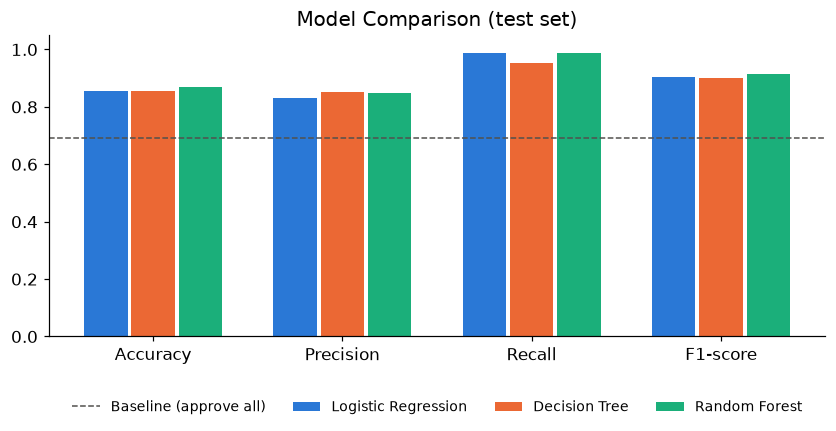

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.2))
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
w = 0.25
x = np.arange(len(metrics))
for i, (name, color) in enumerate(zip(results_df.index, [APPROVED, REJECTED, THIRD])):
    ax.bar(x + (i - 1) * w, results_df.loc[name, metrics], w - 0.02, color=color, label=name)
ax.axhline(baseline, color="#52514e", linestyle="--", linewidth=1, label="Baseline (approve all)")
ax.set_xticks(x, metrics)
ax.set_ylim(0, 1.05)
ax.set_title("Model Comparison (test set)")
ax.legend(frameon=False, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.3), fontsize=9)
save(fig, "07_model_comparison")

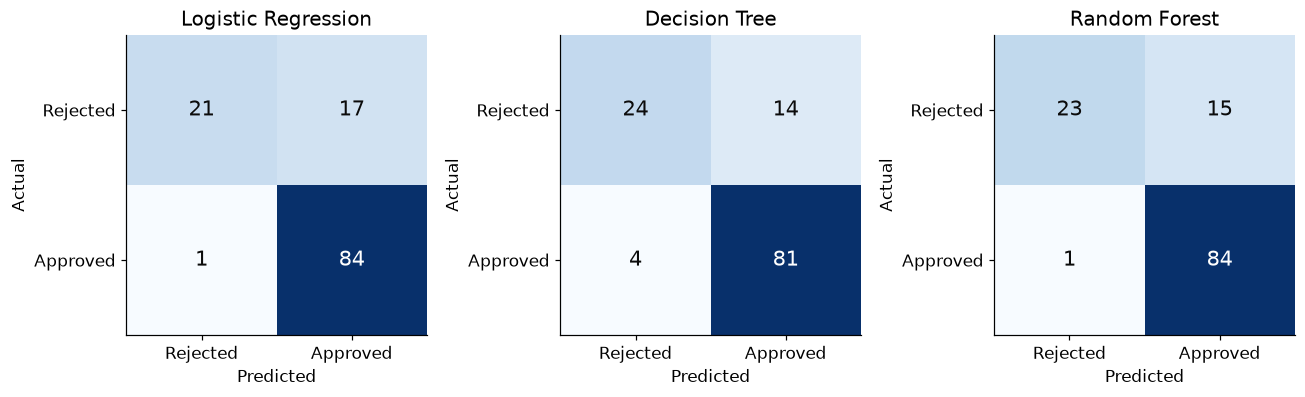

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, preds[name])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                    color="white" if cm[i, j] > cm.max() / 2 else "#0b0b0b")
    ax.set_xticks([0, 1], ["Rejected", "Approved"])
    ax.set_yticks([0, 1], ["Rejected", "Approved"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(name)
save(fig, "08_confusion_matrices")

## 9. Interpretation
**What happened?** All three models clearly beat the 69% "approve everyone" baseline. **Random Forest is best** on test accuracy (87%), F1 (0.91) and cross-validation (81%). Logistic Regression is very close.

All models have very high recall but weaker performance on the **Rejected** class (see confusion matrices) — they sometimes approve applicants who were actually rejected, mainly because Rejected cases are the minority.

**Why?** Feature importance below shows the model relies mostly on **Credit_History**, followed by income/loan-size features.

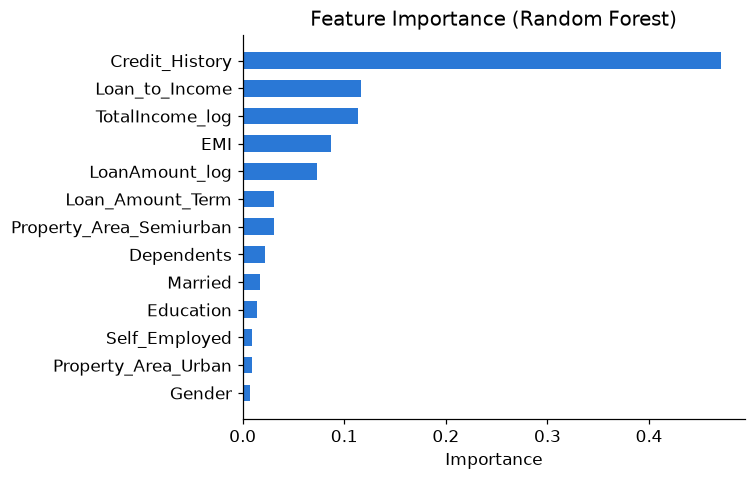

Credit_History             0.471
Loan_to_Income             0.117
TotalIncome_log            0.113
EMI                        0.086
LoanAmount_log             0.073
Loan_Amount_Term           0.031
Property_Area_Semiurban    0.031
Dependents                 0.022
Married                    0.017
Education                  0.014
Self_Employed              0.009
Property_Area_Urban        0.009
Gender                     0.007
dtype: float64

In [17]:
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(imp.index, imp.values, color=APPROVED, height=0.6)
ax.set_title("Feature Importance (Random Forest)")
ax.set_xlabel("Importance")
save(fig, "09_feature_importance")
imp.sort_values(ascending=False).round(3)

In [18]:
lr = models["Logistic Regression"]
coef = pd.Series(lr.coef_[0], index=X.columns).sort_values(ascending=False).round(3)
print("Logistic Regression coefficients (+ helps approval, - hurts approval):\n", coef)

Logistic Regression coefficients (+ helps approval, - hurts approval):
 Credit_History             1.241
Property_Area_Semiurban    0.373
LoanAmount_log             0.333
Married                    0.245
Education                  0.164
Dependents                 0.116
Property_Area_Urban        0.064
Loan_Amount_Term          -0.004
EMI                       -0.043
Self_Employed             -0.075
Gender                    -0.085
Loan_to_Income            -0.330
TotalIncome_log           -0.416
dtype: float64


**So what? (Real-world meaning)**
- Applicants with a **good credit history** can be fast-tracked; those with no/bad history need manual review.
- **Loan size compared to income** matters more than income alone.
- The model can act as a **first-level screening tool** for HDFC loan officers — not a replacement for them.

### Try the model on a new applicant

In [19]:
def predict_applicant(gender, married, dependents, education, self_employed,
                      applicant_income, coapplicant_income, loan_amount,
                      loan_term, credit_history, property_area):
    total = applicant_income + coapplicant_income
    row = {"Gender": gender, "Married": married, "Dependents": dependents,
           "Education": education, "Self_Employed": self_employed,
           "Loan_Amount_Term": loan_term, "Credit_History": credit_history,
           "TotalIncome_log": np.log(total), "LoanAmount_log": np.log(loan_amount),
           "EMI": loan_amount / loan_term, "Loan_to_Income": loan_amount / total,
           "Property_Area_Semiurban": int(property_area == "Semiurban"),
           "Property_Area_Urban": int(property_area == "Urban")}
    x = pd.DataFrame([row])[X.columns]
    prob = rf.predict_proba(x)[0, 1]
    return ("Approved" if prob >= 0.5 else "Rejected"), round(prob, 2)

print("Good credit:", predict_applicant(1, 1, 0, 1, 0, 5000, 1500, 120, 360, 1, "Semiurban"))
print("Bad credit: ", predict_applicant(1, 1, 0, 1, 0, 5000, 1500, 120, 360, 0, "Semiurban"))

Good credit: ('Approved', np.float64(0.82))
Bad credit:  ('Rejected', np.float64(0.21))


## 10. Limitations & Improvements
- **Small dataset** (614 rows) → results may change with a different split.
- **Imbalanced target** → model is weaker at catching Rejected cases. *Improvement:* class weights or SMOTE.
- **Heavy dependence on Credit_History** → first-time borrowers with no history may be treated unfairly.
- **Missing important features** like existing debts, CIBIL score, employer type, age. *Improvement:* add them.
- Could tune hyperparameters (GridSearchCV) and try more models (e.g., XGBoost).

## 11. Conclusion
We built a classification model that predicts loan approval with **87% test accuracy** (81% average in 5-fold cross-validation), clearly better than the 69% baseline.
**Credit history** is by far the most important factor, followed by loan-to-income ratio and total income.
**Random Forest** is chosen as the final model because it scored best on accuracy, F1 and cross-validation. Logistic Regression is a close second and is useful when the bank needs a simple, explainable model.